# F8 · Pan-cancer programme queries

* **Needs:** `R8_pan_cancer.ipynb` (results/pan_cancer/).
* **Writes:** `figures/fig8_pan_cancer/panels/{A,B,CD}.{pdf,png}` and `figures/fig8_pan_cancer/fig8_pan_cancer.{pdf,png}`.

**Shown rule** (stated in the caption): the programmes whose Spindle-naive hits gain in match to the query
(gain > 1e-3) and score above the other tiles (δ > 0) in all five sections, using means over seeds from `programs.csv`.
The others are reported in the text.

Panels:
* **A:** the query, i.e. the breast exemplar's correlation R_S on the programme genes (diagonal blank).
* **B:** seed 0, the closeness of each section's tissue to the query, as a smoothed rank gradient. A programme absent
  from a section (Spindle-naive's mean δ ≤ 0) is drawn faded.
* **C, D:** every section × shown programme, mean ± s.d. over seeds 0–4, for the hits (5 % of the index tiles) of
  Spindle-naive and of Spindle. C is the gain in match to R_S, D the co-variation lift over the hits' cells; variances
  only appear as a grey tick.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import numpy as np
import pandas as pd
from matplotlib import colormaps
from matplotlib.cm import ScalarMappable
from matplotlib.colors import ListedColormap, Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

import style as ps

FIG = "fig8_pan_cancer"
RES = ps.ROOT / "results" / "pan_cancer"
KEYS = ["breast_cancer", "lung_cancer", "pancreatic_cancer", "brain_cancer", "skin_melanoma"]
PROGS = ["Cytotoxic_T", "Myeloid", "Stromal_Perivascular", "B_Plasma"]
PROG_LABELS = {"Cytotoxic_T": "Cytotoxic T", "Myeloid": "Myeloid", "Stromal_Perivascular": "Stromal / perivascular",
               "B_Plasma": "B / plasma"}
PROG_COLORS = {"Cytotoxic_T": "#CC3311", "Myeloid": "#009988", "Stromal_Perivascular": "#0077BB",
               "B_Plasma": "#EE7733"}
GREY = "#E3E3E3"
CELL_MM = 2.3  # heatmap cell
GRAD_W = {"breast_cancer": 36.0, "lung_cancer": 48.0, "pancreatic_cancer": 48.0, "brain_cancer": 31.0,
          "skin_melanoma": 33.0}  # map widths (mm); lung over pancreas in one column
COLS = [("breast_cancer", 1, 0, "Breast"), ("lung_cancer", 39, 0, "Lung"), ("pancreatic_cancer", 39, 19.2, "Pancreas"),
        ("brain_cancer", 89, 0, "Brain"), ("skin_melanoma", 122, 0, "Skin")]  # (key, x in panel B, dy in row, label)
Y0, STEP = 8.0, 35.0  # first query row, row step
GAIN_EPS = 1e-3
SMOOTH = 2.0  # Gaussian s.d. in median tile sides
PIX = 1 / 3  # pixel in median tile sides
ABSENT_ALPHA = 0.3
GRAD_STEPS = 32


def at(fig, x, y, w, h, **kw):
    """Axes w x h mm at (x, y) mm from the panel's top-left corner."""
    W, H = ps.size_mm(fig)
    return fig.add_axes([x / W, 1 - (y + h) / H, w / W, h / H], **kw)


def text(fig, x, y, s, size=ps.LABEL_PT, ha="left", **kw):
    W, H = ps.size_mm(fig)
    fig.text(x / W, 1 - y / H, s, fontsize=size, ha=ha, va="top", **kw)


def hbar(fig, x, y, w, cmap, vmin, vmax, ticks):
    ax = at(fig, x, y, w, 2.5)
    cb = fig.colorbar(ScalarMappable(Normalize(vmin, vmax), cmap), cax=ax, orientation="horizontal", ticks=ticks)
    cb.outline.set_linewidth(0.5)
    return cb


T = pd.read_csv(RES / "programs.csv")
N = T[T.method == "naive_partial"]
ok = N.assign(ok=(N.gain > GAIN_EPS) & (N.delta > 0)).groupby("program").ok.all()
SHOWN = [p for p in PROGS if p in ok.index and ok[p]]
ABSENT = set(map(tuple, N[N.absent][["key", "program"]].to_numpy()))
print("shown:", SHOWN, "| absent (section, programme):", sorted(ABSENT))

shown: ['Myeloid', 'Stromal_Perivascular'] | absent (section, programme): [('brain_cancer', 'Cytotoxic_T'), ('skin_melanoma', 'B_Plasma')]


## A · The queries

figures/fig8_pan_cancer/panels/A.pdf/.png: 24 x 90 mm, 0.0 / 0.2 MB


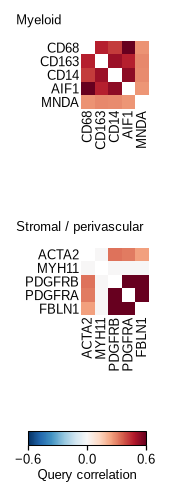

In [2]:
A_W, A_H = 24.0, 90.0


def panel_a(fig):
    z = np.load(RES / "exemplar.npz")
    E = pd.read_csv(RES / "exemplar.csv").set_index("program")
    for i, p in enumerate(SHOWN):
        y = Y0 + STEP * i
        text(fig, 0, y, PROG_LABELS[p], size=ps.TICK_PT)
        R = z[f"R_{p}"].copy()
        np.fill_diagonal(R, np.nan)
        genes = E.loc[p, "genes"].split()
        s = len(genes)
        ax = at(fig, 11, y + 4.5, s * CELL_MM, s * CELL_MM)
        ax.imshow(R, cmap=ps.DIVERGING, vmin=-0.6, vmax=0.6, interpolation="nearest")
        ax.set_xticks(range(s))
        ax.set_xticklabels(genes, rotation=90)
        ax.set_yticks(range(s))
        ax.set_yticklabels(genes)
        ax.tick_params(length=0, pad=1)
        for sp in ax.spines.values():
            sp.set_visible(False)
    hbar(fig, 2, 78.5, 20, ps.DIVERGING, -0.6, 0.6, [-0.6, 0, 0.6])
    text(fig, 12, 85, "Query correlation", size=ps.TICK_PT, ha="center")


fig = ps.panel(A_W, A_H)
panel_a(fig)
ps.save_panel(fig, FIG, "A")

## B · Closeness of every section to the query (seed 0)

figures/fig8_pan_cancer/panels/B.pdf/.png: 156 x 90 mm, 0.8 / 1.9 MB


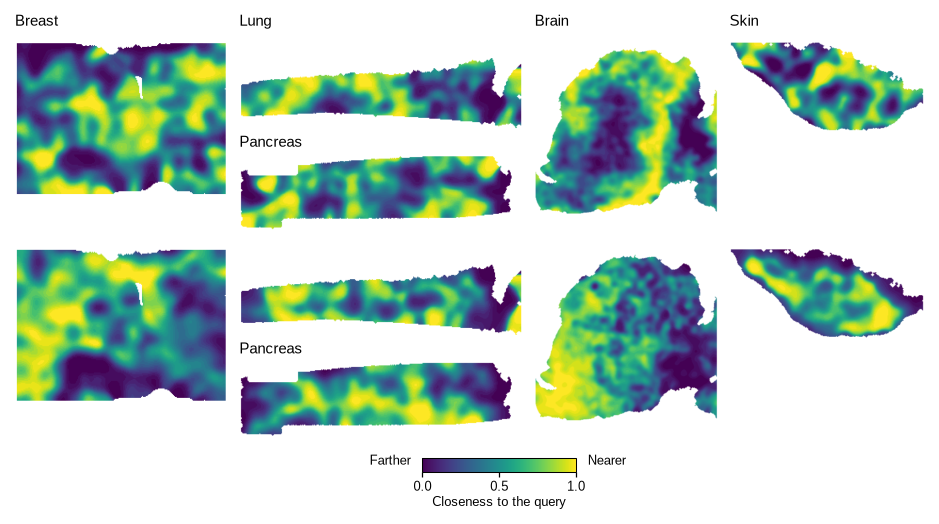

In [3]:
B_W, B_H = 156.0, 90.0


def gradient_image(z, prog):
    """Closeness of the tissue to a query: every index tile's d_B^S percentile within the section (1 = nearest),
    weighted by tile area, smoothed over tile centres with a Gaussian of SMOOTH tile sides (Nadaraya-Watson on a
    grid of PIX tile sides), masked to the pixels with cells (closed, so held-out and dropped tiles are filled), then
    ranked over the tissue pixels: the share of the section's tissue farther from the query."""
    from scipy.ndimage import binary_closing, binary_fill_holes, gaussian_filter, label
    from scipy.stats import rankdata

    xy, ctr, side = z["xy"], z["centre"], z["side"]
    d = z[f"d_{prog}"]
    v = 1 - (rankdata(d) - 1) / (len(d) - 1)
    px = PIX * np.median(side)
    (x0, y0), (x1, y1) = xy.min(0), xy.max(0)
    bx, by = np.arange(x0, x1 + px, px), np.arange(y0, y1 + px, px)
    w = side ** 2
    num, _, _ = np.histogram2d(ctr[:, 1], ctr[:, 0], [by, bx], weights=w * v)
    den, _, _ = np.histogram2d(ctr[:, 1], ctr[:, 0], [by, bx], weights=w)
    s = SMOOTH / PIX
    img = gaussian_filter(num, s) / np.maximum(gaussian_filter(den, s), 1e-12)
    occ, _, _ = np.histogram2d(xy[:, 1], xy[:, 0], [by, bx])
    mask = binary_fill_holes(binary_closing(occ > 0, iterations=2)) & (gaussian_filter(den, s) > 1e-3 * den.max())
    lab, _ = label(mask)
    size = np.bincount(lab.ravel())
    mask &= np.isin(lab, np.flatnonzero(size >= 0.01 * mask.sum())) & (lab > 0)  # stray cells off the section
    out = np.full(img.shape, np.nan)
    out[mask] = (rankdata(img[mask]) - 1) / (mask.sum() - 1)
    return out, (x0, x1, y0, y1)


IMAGES = {}  # (key, programme) -> gradient image, computed once for the panel and the page
for key in KEYS:
    z = np.load(RES / "per_dataset" / key / "seed0_gradient.npz", allow_pickle=True)
    for p in SHOWN:
        IMAGES[key, p] = gradient_image(z, p)


def panel_b(fig):
    cmap = ListedColormap(colormaps["viridis"](np.linspace(0, 1, GRAD_STEPS)))  # steps keep the PNGs in budget
    for key, x, dy, label in COLS:
        if dy == 0:
            text(fig, x, 3.5, label)
    for i, p in enumerate(SHOWN):
        y = Y0 + STEP * i
        for key, x, dy, label in COLS:
            img, (x0, x1, y0, y1) = IMAGES[key, p]
            w = GRAD_W[key]
            ax = at(fig, x, y + dy, w, w * (y1 - y0) / (x1 - x0))
            ax.imshow(img, cmap=cmap, vmin=0, vmax=1, extent=(x0, x1, y1, y0), interpolation="bilinear",
                      origin="upper", alpha=ABSENT_ALPHA if (key, p) in ABSENT else 1.0)
            ax.set_xlim(x0, x1)
            ax.set_ylim(y1, y0)
            ax.axis("off")
            if dy:
                text(fig, x, y + dy - 3.2, label)
    hbar(fig, 70, 78.5, 26, colormaps["viridis"], 0, 1, [0, 0.5, 1])
    text(fig, 68, 78.0, "Farther", size=ps.TICK_PT, ha="right")
    text(fig, 98, 78.0, "Nearer", size=ps.TICK_PT)
    text(fig, 83, 85, "Closeness to the query", size=ps.TICK_PT, ha="center")


fig = ps.panel(B_W, B_H)
panel_b(fig)
ps.save_panel(fig, FIG, "B")

## C, D · Gain in match to the query and co-variation lift on every section
One panel with two axes and their shared legend.

figures/fig8_pan_cancer/panels/CD.pdf/.png: 180 x 52 mm, 0.0 / 0.4 MB


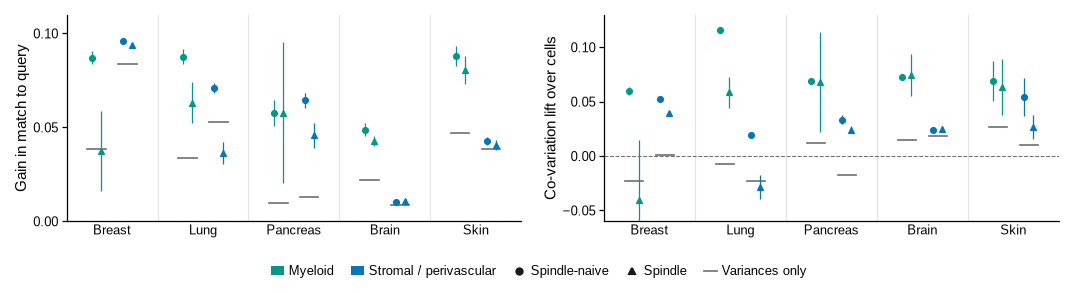

In [4]:
CD_W, CD_H = 180.0, 52.0


def panel_cd(fig):
    P = T.set_index(["key", "program", "method"])
    off = {p: d for p, d in zip(SHOWN, np.linspace(-0.17, 0.17, len(SHOWN)) if len(SHOWN) > 1 else [0.0])}
    for x0, col, ylab, lim, ticks in ((0, "gain", "Gain in match to query", (0, 0.11), [0, 0.05, 0.1]),
                                      (91, "lift", "Co-variation lift over cells", (-0.06, 0.13),
                                       [-0.05, 0, 0.05, 0.1])):
        ax = at(fig, x0 + 10, 5.5, 77, 35)
        ax.axhline(0, color=ps.MUTED, lw=0.5, ls="--", zorder=1)
        for i, key in enumerate(KEYS):
            for p in SHOWN:
                x, c = i + off[p], PROG_COLORS[p]
                ax.plot([x - 0.1, x + 0.1], [P.loc[(key, p, "D"), col]] * 2, color=ps.MUTED, lw=0.8, zorder=2)
                for m, mk, dx in (("naive_partial", "o", -0.05), ("spindle_partial", "^", 0.05)):
                    r = P.loc[(key, p, m)]
                    ax.errorbar(x + dx, r[col], yerr=r[f"{col}_sd"] if np.isfinite(r[f"{col}_sd"]) else 0, fmt=mk,
                                ms=2.8 if m == "naive_partial" else 3.0, color=c, mew=0.6, elinewidth=0.6, capsize=0,
                                zorder=3)
        ax.set_xticks(range(len(KEYS)))
        ax.set_xticklabels([ps.DATASET_LABELS[k] for k in KEYS])
        ax.tick_params(axis="x", length=0)
        ax.set_xlim(-0.5, len(KEYS) - 0.5)
        for i in range(1, len(KEYS)):
            ax.axvline(i - 0.5, color=GREY, lw=0.5, zorder=0)
        ax.set_ylim(*lim)
        ax.set_yticks(ticks)
        ax.set_ylabel(ylab)
    W, H = ps.size_mm(fig)
    fig.legend(handles=[Patch(fc=PROG_COLORS[p], ec="none", label=PROG_LABELS[p]) for p in SHOWN]
               + [Line2D([], [], ls="", marker="o", ms=3, color=ps.INK, label="Spindle-naive"),
                  Line2D([], [], ls="", marker="^", ms=3, color=ps.INK, label="Spindle"),
                  Line2D([], [], ls="-", lw=0.8, color=ps.MUTED, label="Variances only")],
               ncol=len(SHOWN) + 3, loc="center", bbox_to_anchor=(0.5, 1 - 49 / H), handlelength=1.0,
               handletextpad=0.4, columnspacing=1.4)


fig = ps.panel(CD_W, CD_H)
panel_cd(fig)
ps.save_panel(fig, FIG, "CD")

## Full figure

figures/fig8_pan_cancer/fig8_pan_cancer.pdf/.png: 180 x 142 mm, 0.9 / 3.0 MB


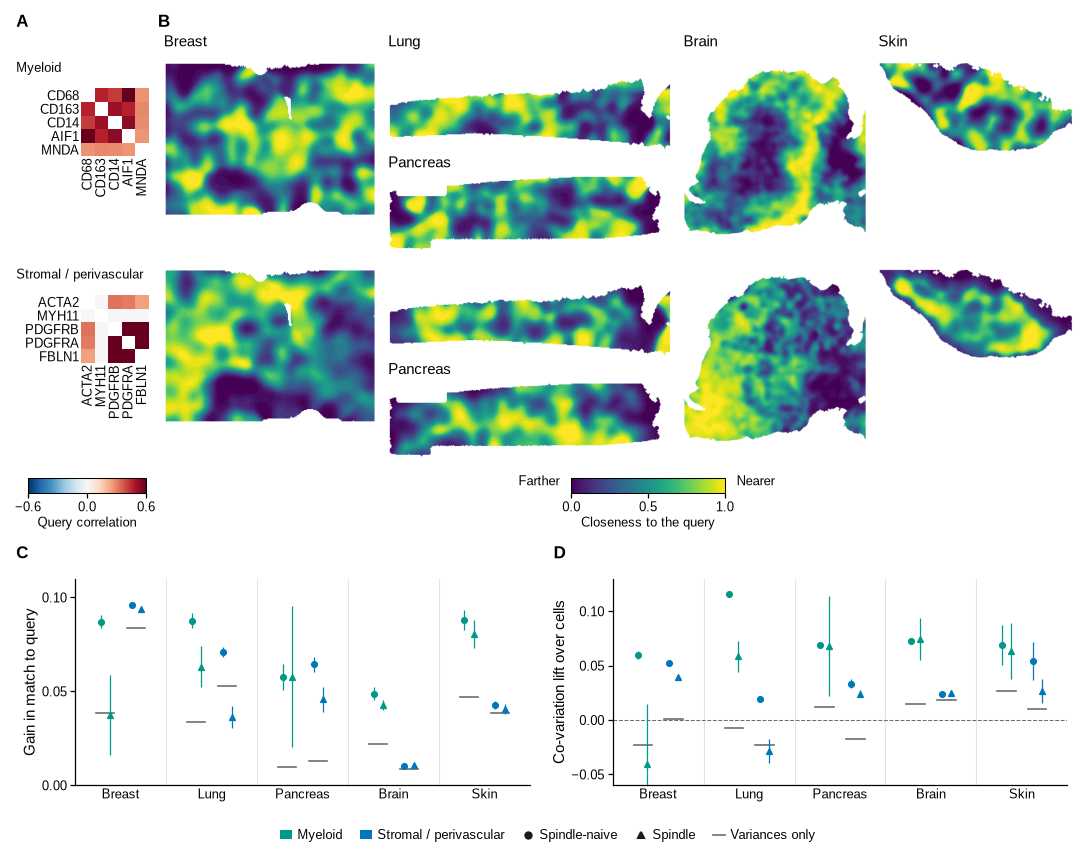

In [5]:
page = ps.page(180, 142)
panel_a(ps.place(page, "A", 0, 0, A_W, A_H))
panel_b(ps.place(page, "B", 24, 0, B_W, B_H))
panel_cd(ps.place(page, "C", 0, 90, CD_W, CD_H))
page.text(91 / 180, 1 - 90 / 142, "D", fontsize=ps.LETTER_PT, fontweight="bold", ha="left", va="top")
ps.save_figure(page, FIG)